# 06 · Comparison of the three solutions

This notebook only reads the saved results of notebooks 03–05 (plus two extra experiments: the selector × classifier swap in §6 and the leakage check in §7). All numbers are **speaker-independent**: every prediction was made by a model that never heard that actor.

In [1]:
import json
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

from ser.config import EMOTION_ORDER, FEATURES_CSV, RANDOM_STATE, RESULTS_DIR
from ser.evaluation import mcnemar, scores
from ser.features import feature_group
from ser.plots import GREY, INK_2, SEQ_CMAP, SOLUTION_COLORS, save, set_style

set_style()

RUNS = {  # display name -> (results slug, classifier, is_solution)
    "Baseline SVM (all features)": ("baseline_svm", "SVM", False),
    "S1: MI + SVM": ("s1", "SVM", True),
    "Baseline RF (all features)": ("baseline_rf", "Random Forest", False),
    "S2: RFE + RF": ("s2", "Random Forest", True),
    "Baseline MLP (all features)": ("baseline_mlp", "MLP", False),
    "S3: GA + MLP": ("s3", "MLP", True),
}
folds = {n: pd.read_csv(RESULTS_DIR / f"{s}_folds.csv") for n, (s, _, _) in RUNS.items()}
oof = {n: pd.read_csv(RESULTS_DIR / f"{s}_oof.csv").sort_values("file", ignore_index=True)
       for n, (s, _, _) in RUNS.items()}
selected = {n: json.load(open(RESULTS_DIR / f"{s}_selected.json"))["selected_per_fold"]
            for n, (s, _, sol) in RUNS.items() if sol}
assert all((o.file.values == oof["S1: MI + SVM"].file.values).all() for o in oof.values())

## 1. Results table
Mean ± standard deviation over the 6 speaker-independent outer folds. "Pooled" accuracy is computed over all 1,440 out-of-fold predictions at once.

In [2]:
rows = []
for n, f in folds.items():
    o = oof[n]
    pooled = scores(o.y_true, o.y_pred)
    rows.append({
        "Model": n,
        "Accuracy": f"{f.accuracy.mean():.3f} ± {f.accuracy.std():.3f}",
        "Macro-F1": f"{f.macro_f1.mean():.3f} ± {f.macro_f1.std():.3f}",
        "UAR": f"{f.uar.mean():.3f} ± {f.uar.std():.3f}",
        "Pooled accuracy": round(pooled["accuracy"], 3),
        "Features used (mean)": round(f.n_features.mean(), 1),
        "Selection time / fold (s)": round(f.select_seconds.mean(), 1),
        "Final model fit (s)": round(f.fit_seconds.mean(), 2),
        "Predict (ms / clip)": round(f.predict_ms_per_clip.mean(), 3),
    })
table = pd.DataFrame(rows).set_index("Model")
table.to_csv(RESULTS_DIR / "summary_table.csv")
table

,Accuracy,Macro-F1,UAR,Pooled accuracy,Features used (mean),Selection time / fold (s),Final model fit (s),Predict (ms / clip)
Model,,,,,,,,
Baseline SVM (all features),0.569 ± 0.077,0.554 ± 0.081,0.562 ± 0.082,0.569,190.0,0.0,0.21,0.211
S1: MI + SVM,0.538 ± 0.060,0.522 ± 0.059,0.531 ± 0.054,0.538,101.7,3.4,0.12,0.204
Baseline RF (all features),0.517 ± 0.066,0.492 ± 0.074,0.510 ± 0.071,0.517,190.0,0.0,3.84,0.115
S2: RFE + RF,0.499 ± 0.094,0.473 ± 0.100,0.491 ± 0.096,0.499,66.7,15.1,1.70,0.079
Baseline MLP (all features),0.533 ± 0.060,0.473 ± 0.054,0.503 ± 0.055,0.533,190.0,0.0,1.34,0.005
S3: GA + MLP,0.543 ± 0.072,0.511 ± 0.077,0.522 ± 0.071,0.543,108.2,647.0,1.68,0.010


## 2. Each solution vs its own baseline
Bars show the mean over the 6 folds and dots show the individual folds. Grey is the same classifier on all 190 features, and colour is the classifier after feature selection.

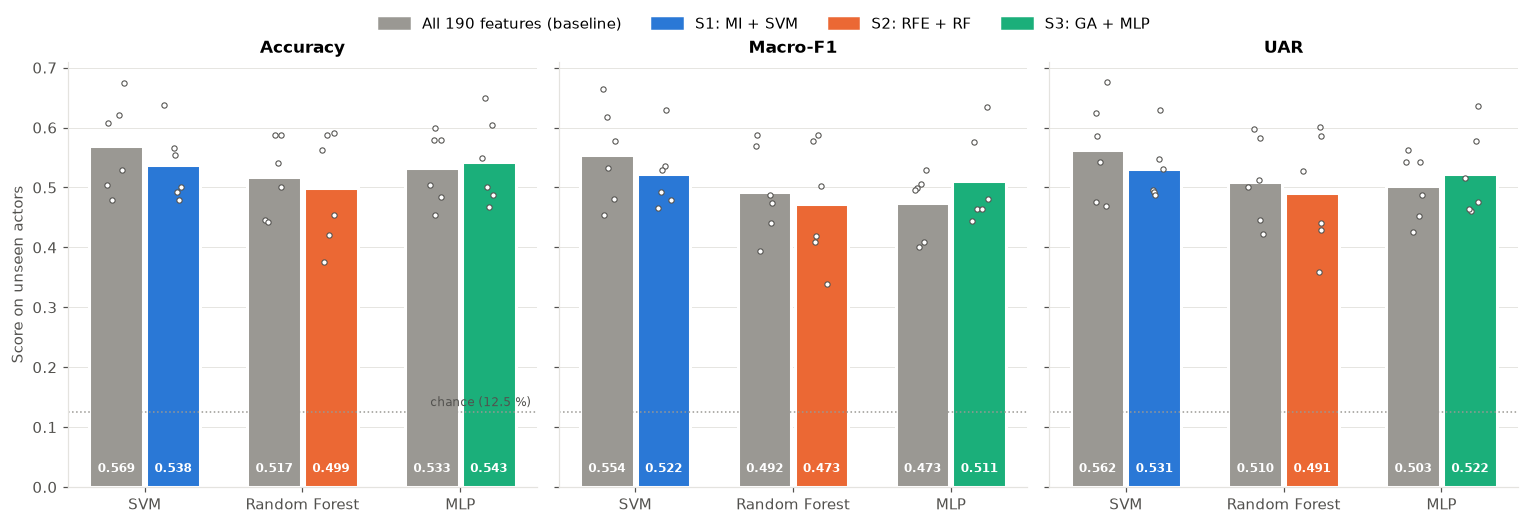

In [3]:
pairs = [("SVM", "Baseline SVM (all features)", "S1: MI + SVM"),
         ("Random Forest", "Baseline RF (all features)", "S2: RFE + RF"),
         ("MLP", "Baseline MLP (all features)", "S3: GA + MLP")]
metrics = [("accuracy", "Accuracy"), ("macro_f1", "Macro-F1"), ("uar", "UAR")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
rng = np.random.default_rng(0)
for ax, (m, mlabel) in zip(axes, metrics):
    for i, (clf, b, s) in enumerate(pairs):
        for j, (name, color) in enumerate([(b, GREY), (s, SOLUTION_COLORS[s])]):
            vals = folds[name][m]
            x = i + (j - 0.5) * 0.36
            ax.bar(x, vals.mean(), width=0.34, color=color, edgecolor="white", linewidth=2)
            ax.scatter(x + rng.uniform(-0.06, 0.06, len(vals)), vals, s=12, color="white",
                       edgecolor=INK_2, linewidth=0.7, zorder=3)
            ax.text(x, 0.025, f"{vals.mean():.3f}", ha="center", fontsize=8, color="white", fontweight="bold")
    ax.set_xticks(range(3), [p[0] for p in pairs])
    ax.set_title(mlabel)
    ax.axhline(1 / 8, color=GREY, lw=1, ls=":")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Score on unseen actors")
axes[0].text(2.45, 1 / 8 + 0.01, "chance (12.5 %)", ha="right", fontsize=8, color=INK_2)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=GREY, label="All 190 features (baseline)")] +
           [Patch(color=SOLUTION_COLORS[s], label=s) for _, _, s in pairs],
           loc="upper center", ncols=4, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save(fig, "12_solutions_vs_baselines")
plt.show()

## 3. Are the differences statistically significant?
**McNemar's exact test** on the 1,440 paired out-of-fold predictions. It counts clips that one model got right and the other got wrong. Because we run six tests, the p-values are corrected with the **Holm–Bonferroni** method. An adjusted p < 0.05 means the two models' error patterns differ by more than chance.

In [4]:
y_true = oof["S1: MI + SVM"].y_true.values
tests = []
compare = [(b, s) for _, b, s in pairs] + list(combinations(["S1: MI + SVM", "S2: RFE + RF", "S3: GA + MLP"], 2))
for a, b in compare:
    r = mcnemar(y_true, oof[a].y_pred.values, oof[b].y_pred.values)
    acc_a, acc_b = (oof[a].y_pred.values == y_true).mean(), (oof[b].y_pred.values == y_true).mean()
    tests.append({"Model A": a, "Model B": b, "Acc A": round(acc_a, 3), "Acc B": round(acc_b, 3),
                  "Only A correct": r["only_a_correct"], "Only B correct": r["only_b_correct"],
                  "p-value": r["p_value"]})
mc = pd.DataFrame(tests)
# Holm-Bonferroni correction, because we run 6 tests at once
order = np.argsort(mc["p-value"].values)
m = len(mc)
adj = np.empty(m)
running = 0.0
for rank, i in enumerate(order):
    running = max(running, min(1.0, (m - rank) * mc["p-value"].values[i]))
    adj[i] = running
mc["Holm-adjusted p"] = adj
mc["Significant (Holm, α=0.05)"] = adj < 0.05
mc.to_csv(RESULTS_DIR / "mcnemar_tests.csv", index=False)
mc.style.format({"p-value": "{:.4f}", "Holm-adjusted p": "{:.4f}"})

,Model A,Model B,Acc A,Acc B,Only A correct,Only B correct,p-value,Holm-adjusted p,"Significant (Holm, α=0.05)"
0,Baseline SVM (all features),S1: MI + SVM,0.569000,0.538000,144,99,0.0047,0.0187,True
1,Baseline RF (all features),S2: RFE + RF,0.517000,0.499000,103,76,0.0517,0.1550,False
2,Baseline MLP (all features),S3: GA + MLP,0.533000,0.543000,121,135,0.4166,0.8331,False
3,S1: MI + SVM,S2: RFE + RF,0.538000,0.499000,206,149,0.0029,0.0145,True
4,S1: MI + SVM,S3: GA + MLP,0.538000,0.543000,171,178,0.7481,0.8331,False
5,S2: RFE + RF,S3: GA + MLP,0.499000,0.543000,151,215,0.0010,0.0058,True


## 4. Which emotions are easy and which are hard?
F1 score per emotion for every model (out-of-fold predictions).

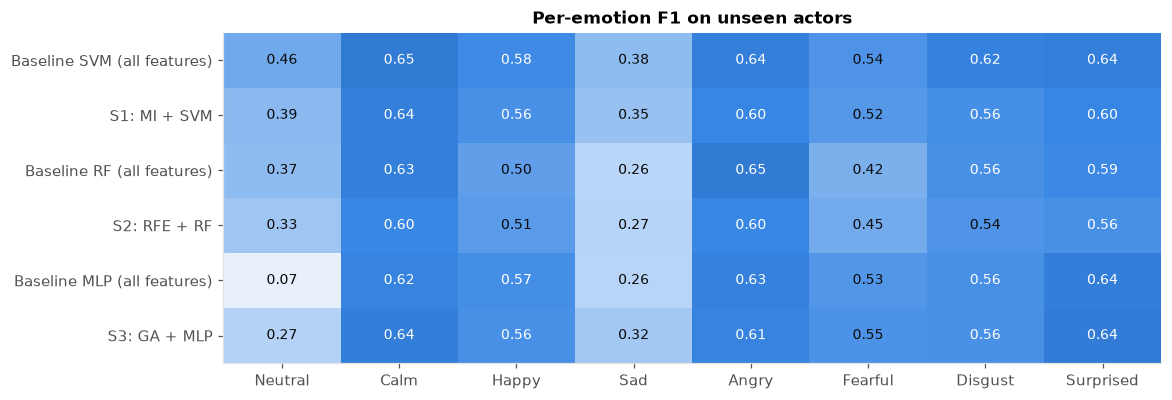

,Neutral,Calm,Happy,Sad,Angry,Fearful,Disgust,Surprised
Baseline SVM (all features),0.456,0.653,0.583,0.376,0.637,0.543,0.625,0.636
S1: MI + SVM,0.388,0.637,0.560,0.350,0.605,0.525,0.563,0.604
Baseline RF (all features),0.373,0.634,0.497,0.257,0.653,0.424,0.559,0.594
S2: RFE + RF,0.332,0.601,0.513,0.265,0.600,0.446,0.539,0.559
Baseline MLP (all features),0.075,0.617,0.567,0.260,0.626,0.534,0.561,0.638
S3: GA + MLP,0.272,0.640,0.562,0.315,0.614,0.549,0.557,0.645


In [5]:
per_class = pd.DataFrame({n: f1_score(o.y_true, o.y_pred, labels=EMOTION_ORDER, average=None)
                          for n, o in oof.items()}, index=[e.capitalize() for e in EMOTION_ORDER]).T
fig, ax = plt.subplots(figsize=(11, 3.9))
ax.imshow(per_class.values, cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
ax.grid(False)
for i in range(per_class.shape[0]):
    for j in range(per_class.shape[1]):
        v = per_class.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.55 else "#0b0b0b")
ax.set_xticks(range(per_class.shape[1]), per_class.columns)
ax.set_yticks(range(per_class.shape[0]), per_class.index)
ax.set_title("Per-emotion F1 on unseen actors")
save(fig, "13_per_class_f1")
plt.show()
per_class.round(3)

## 5. What did the three selectors choose?
For each method we take the **stable** features, those picked in at least 4 of the 6 outer folds.

**(a) Overlap between methods.** An UpSet-style chart: each bar counts the features that belong to exactly the combination of methods marked by the dots below it.

S1: MI + SVM    0.604
S2: RFE + RF    0.461
S3: GA + MLP    0.476 

S1: MI + SVM: 85 stable features
S2: RFE + RF: 39 stable features
S3: GA + MLP: 95 stable features


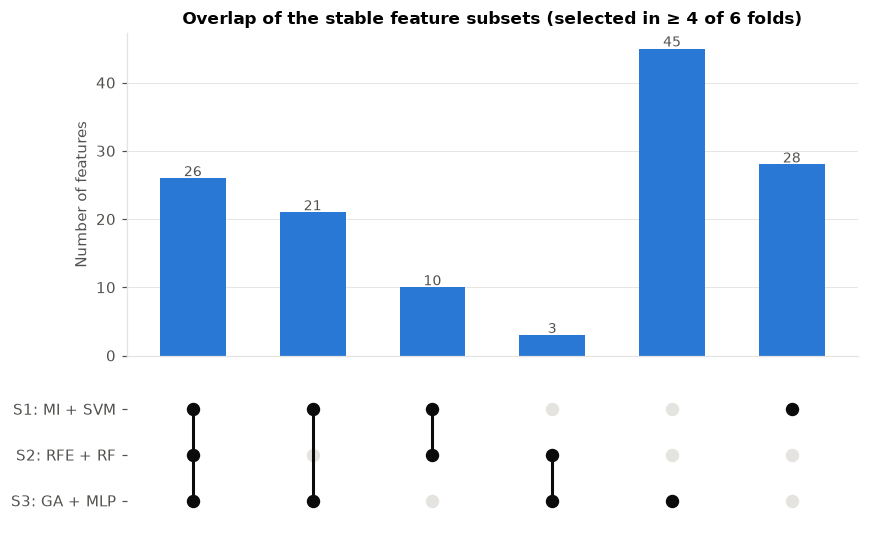

Features chosen by all three methods: ['centroid_mean', 'contrast_02_mean', 'contrast_03_mean', 'contrast_04_mean', 'contrast_06_std', 'f0_max', 'f0_mean', 'f0_min', 'f0_range', 'f0_std', 'flatness_mean', 'mfcc_02_mean', 'mfcc_03_mean', 'mfcc_04_std', 'mfcc_05_mean', 'mfcc_05_std', 'mfcc_19_std', 'mfcc_d1_04_mean', 'mfcc_d1_05_std', 'mfcc_d2_01_std', 'mfcc_d2_18_std', 'mfcc_d2_19_std', 'mfcc_d2_20_std', 'rolloff_mean', 'rolloff_std', 'voiced_ratio']


In [6]:
sol_names = ["S1: MI + SVM", "S2: RFE + RF", "S3: GA + MLP"]

# Selection stability: mean Jaccard similarity between the subsets chosen in different folds
# (1 = identical subsets every fold, 0 = no overlap at all)
stab = {}
for n in sol_names:
    sets = [set(s) for s in selected[n]]
    stab[n] = np.mean([len(a & b) / len(a | b) for a, b in combinations(sets, 2)])
stability = pd.Series(stab, name="mean pairwise Jaccard across folds").round(3)
stability.to_csv(RESULTS_DIR / "selection_stability.csv")
print(stability.to_string(), "\n")

stable = {}
for n in sol_names:
    cnt = pd.Series([f for fold in selected[n] for f in fold]).value_counts()
    stable[n] = set(cnt[cnt >= 4].index)
    print(f"{n}: {len(stable[n])} stable features")

all_feats = set().union(*stable.values())
combos = {}
for f in all_feats:
    key = tuple(f in stable[n] for n in sol_names)
    combos[key] = combos.get(key, 0) + 1
combos = sorted(combos.items(), key=lambda kv: (-sum(kv[0]), -kv[1]))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
xs = range(len(combos))
ax1.bar(xs, [c for _, c in combos], color="#2a78d6", width=0.55)
for x, (_, c) in zip(xs, combos):
    ax1.text(x, c + 0.3, str(c), ha="center", fontsize=9, color=INK_2)
ax1.set_ylabel("Number of features")
ax1.set_title("Overlap of the stable feature subsets (selected in ≥ 4 of 6 folds)")
ax1.grid(axis="x", visible=False)
for x, (key, _) in zip(xs, combos):
    on = [i for i, k in enumerate(key) if k]
    ax2.scatter([x] * 3, range(3), s=60, color="#e4e3df", zorder=2)
    ax2.scatter([x] * len(on), on, s=60, color="#0b0b0b", zorder=3)
    if len(on) > 1:
        ax2.plot([x, x], [min(on), max(on)], color="#0b0b0b", lw=2, zorder=2)
ax2.set_yticks(range(3), sol_names)
ax2.set_ylim(-0.6, 2.6)
ax2.invert_yaxis()
ax2.grid(False)
ax2.set_xticks([])
for s in ax2.spines.values():
    s.set_visible(False)
fig.tight_layout()
save(fig, "14_selected_feature_overlap")
plt.show()
print("Features chosen by all three methods:", sorted(set.intersection(*stable.values())))

**(b) Feature families.** Share of each acoustic family in every method's selection (all folds), compared with its share among all 190 features. A bar longer than the grey one means the method favours that family.

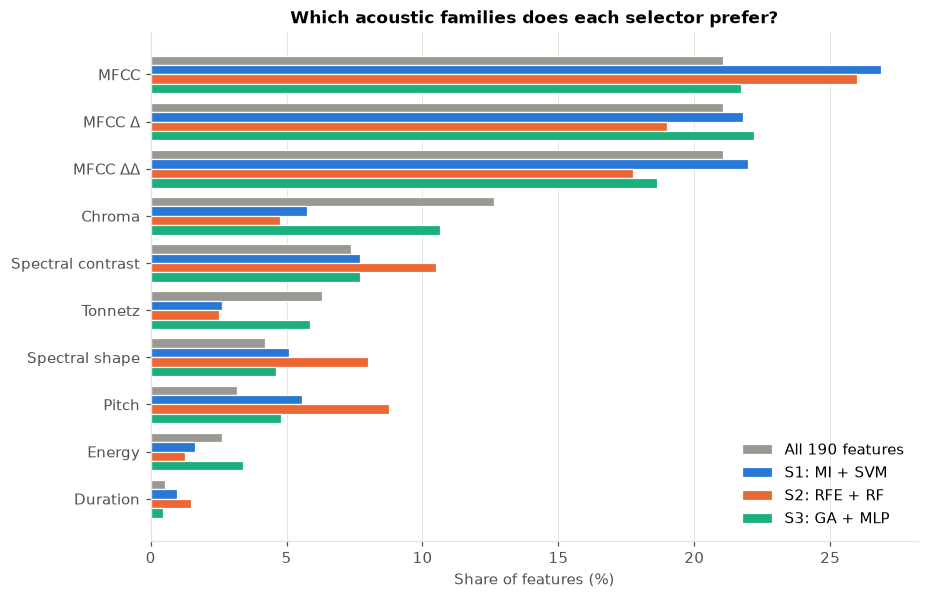

,All 190 features,S1: MI + SVM,S2: RFE + RF,S3: GA + MLP
Duration,0.5,1.0,1.5,0.5
Energy,2.6,1.6,1.2,3.4
Pitch,3.2,5.6,8.8,4.8
Spectral shape,4.2,5.1,8.0,4.6
Tonnetz,6.3,2.6,2.5,5.9
Spectral contrast,7.4,7.7,10.5,7.7
Chroma,12.6,5.7,4.8,10.6
MFCC ΔΔ,21.1,22.0,17.8,18.6
MFCC Δ,21.1,21.8,19.0,22.2
MFCC,21.1,26.9,26.0,21.7


In [7]:
df_feats = pd.read_csv(FEATURES_CSV, nrows=1)
META = ["file", "actor", "gender", "emotion_id", "emotion", "intensity", "statement", "repetition"]
ALL = [c for c in df_feats.columns if c not in META]
fam_all = pd.Series([feature_group(f) for f in ALL]).value_counts(normalize=True) * 100
fam = pd.DataFrame({"All 190 features": fam_all})
for n in sol_names:
    fam[n] = pd.Series([feature_group(f) for fold in selected[n] for f in fold]).value_counts(normalize=True) * 100
fam = fam.fillna(0).sort_values("All 190 features")

fig, ax = plt.subplots(figsize=(9, 6))
h = 0.2
y0 = np.arange(len(fam))
for i, col in enumerate(fam.columns):
    color = GREY if i == 0 else SOLUTION_COLORS[col]
    ax.barh(y0 + (1.5 - i) * h, fam[col], height=h, color=color, label=col, edgecolor="white", linewidth=0.8)
ax.set_yticks(y0, fam.index)
ax.set_xlabel("Share of features (%)")
ax.set_title("Which acoustic families does each selector prefer?")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "15_feature_family_share")
plt.show()
fam.round(1)

## 6. Is it the selector or the classifier?
Each solution changes both the selector *and* the classifier, so we also run the two "swapped" combinations with the identical protocol: **MI + Random Forest** and **RFE + SVM**. Together with S1 and S2 this forms a 2 × 2 table that separates the effect of the selector from the effect of the classifier.

In [8]:
from ser.evaluation import nested_ranked_cv, rank_mutual_info, rank_rfe_rf
from ser.models import K_GRID, RF_GRID, SVM_GRID, make_rf, make_svm

data = pd.read_csv(FEATURES_CSV)
X, y, actors = data[ALL].to_numpy(), data["emotion"].to_numpy(), data["actor"].to_numpy()
import re


def run_or_load(name, run):
    """Re-use saved fold results if this experiment was already run (it takes ~30 min)."""
    path = RESULTS_DIR / (re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_") + "_folds.csv")
    if path.exists():
        print(f"{name}: loaded saved results from {path.name}")
        return pd.read_csv(path)
    r = run()
    r.save()
    return r.folds


swap_mi_rf = run_or_load("Ablation MI + RF", lambda: nested_ranked_cv(
    "Ablation MI + RF", X, y, actors, ALL, rank_mutual_info, make_rf, RF_GRID, k_grid=K_GRID,
    files=data.file, outer_curve=False))
swap_rfe_svm = run_or_load("Ablation RFE + SVM", lambda: nested_ranked_cv(
    "Ablation RFE + SVM", X, y, actors, ALL, rank_rfe_rf, make_svm, SVM_GRID, k_grid=K_GRID,
    files=data.file, outer_curve=False))

grid = pd.DataFrame(
    {"SVM": [folds["S1: MI + SVM"].macro_f1.mean(), swap_rfe_svm.macro_f1.mean(),
             folds["Baseline SVM (all features)"].macro_f1.mean()],
     "Random Forest": [swap_mi_rf.macro_f1.mean(), folds["S2: RFE + RF"].macro_f1.mean(),
                       folds["Baseline RF (all features)"].macro_f1.mean()]},
    index=["Mutual Information", "RFE (RF importances)", "No selection (all 190)"])
grid.to_csv(RESULTS_DIR / "ablation_selector_x_classifier.csv")
grid.round(3).rename_axis("Macro-F1 on unseen actors")

Ablation MI + RF: loaded saved results from ablation_mi_rf_folds.csv
Ablation RFE + SVM: loaded saved results from ablation_rfe_svm_folds.csv


,SVM,Random Forest
Macro-F1 on unseen actors,,
Mutual Information,0.522,0.488
RFE (RF importances),0.568,0.473
No selection (all 190),0.554,0.492


**Choice of k rule.** S1 and S2 pick k with the one-standard-error rule. We first ran them with the plain "highest inner score" rule (saved in `results/argmax_rule/`). Both are shown here so the effect of that choice is visible. The rule only uses inner-fold scores, never the test actors.

In [9]:
rule_rows = []
for slug, name in [("s1", "S1: MI + SVM"), ("s2", "S2: RFE + RF")]:
    for rule, d in [("Highest inner score (first run)", RESULTS_DIR / "argmax_rule"), ("One-standard-error rule (final)", RESULTS_DIR)]:
        f = pd.read_csv(d / f"{slug}_folds.csv")
        rule_rows.append({"Solution": name, "k rule": rule, "Mean k": round(f.n_features.mean(), 1),
                          "Accuracy": round(f.accuracy.mean(), 3), "Macro-F1": round(f.macro_f1.mean(), 3),
                          "UAR": round(f.uar.mean(), 3)})
rules = pd.DataFrame(rule_rows)
rules.to_csv(RESULTS_DIR / "k_rule_comparison.csv", index=False)
rules

,Solution,k rule,Mean k,Accuracy,Macro-F1,UAR
0,S1: MI + SVM,Highest inner score (first run),183.3,0.573,0.558,0.568
1,S1: MI + SVM,One-standard-error rule (final),101.7,0.538,0.522,0.531
2,S2: RFE + RF,Highest inner score (first run),120.0,0.517,0.490,0.510
3,S2: RFE + RF,One-standard-error rule (final),66.7,0.499,0.473,0.491


## 6b. Secondary analysis: per-speaker feature normalisation
A widely used SER technique is to standardise each speaker's features using statistics from that speaker's own speech (e.g. Busso et al., 2013). Here every actor's 190 features are z-scored using only that actor's 60 clips, **without labels**, and then the main protocol is run unchanged.

**Caveat: this analysis is transductive.** It assumes some unlabeled speech from each test speaker is available (for example from an enrolment step). In RAVDESS every actor has a perfectly balanced mix of emotions, which real enrolment audio would not have, so the gain shown here is an **upper bound**. The main results above do not use this step.

In [10]:
from ser.models import MLP_GRID, make_mlp
from ser.evaluation import rank_all

Xn = data[ALL].groupby(data["actor"]).transform(lambda c: (c - c.mean()) / (c.std() + 1e-9)).to_numpy()
spk = {}
for label, ranker, mk, grid, kg in [
        ("SpkNorm Baseline SVM", rank_all, make_svm, SVM_GRID, [len(ALL)]),
        ("SpkNorm S1 MI + SVM", rank_mutual_info, make_svm, SVM_GRID, K_GRID),
        ("SpkNorm Baseline RF", rank_all, make_rf, RF_GRID, [len(ALL)]),
        ("SpkNorm Baseline MLP", rank_all, make_mlp, MLP_GRID, [len(ALL)])]:
    spk[label] = run_or_load(label, lambda: nested_ranked_cv(
        label, Xn, y, actors, ALL, ranker, mk, grid, k_grid=kg, files=data.file,
        outer_curve=False, verbose=False))

ref = {"SpkNorm Baseline SVM": "Baseline SVM (all features)", "SpkNorm S1 MI + SVM": "S1: MI + SVM",
       "SpkNorm Baseline RF": "Baseline RF (all features)", "SpkNorm Baseline MLP": "Baseline MLP (all features)"}
spk_table = pd.DataFrame([{
    "Model": ref[k], "Mean k": round(v.n_features.mean(), 1),
    "Macro-F1 (main protocol)": round(folds[ref[k]].macro_f1.mean(), 3),
    "Macro-F1 (+ speaker normalisation)": round(v.macro_f1.mean(), 3),
    "Accuracy (+ speaker normalisation)": round(v.accuracy.mean(), 3)} for k, v in spk.items()])
spk_table["Gain"] = (spk_table["Macro-F1 (+ speaker normalisation)"] - spk_table["Macro-F1 (main protocol)"]).round(3)
spk_table.to_csv(RESULTS_DIR / "speaker_normalisation.csv", index=False)
spk_table

SpkNorm Baseline SVM: loaded saved results from spknorm_baseline_svm_folds.csv
SpkNorm S1 MI + SVM: loaded saved results from spknorm_s1_mi_svm_folds.csv
SpkNorm Baseline RF: loaded saved results from spknorm_baseline_rf_folds.csv
SpkNorm Baseline MLP: loaded saved results from spknorm_baseline_mlp_folds.csv


,Model,Mean k,Macro-F1 (main protocol),Macro-F1 (+ speaker normalisation),Accuracy (+ speaker normalisation),Gain
0,Baseline SVM (all features),190.0,0.554,0.617,0.630,0.063
1,S1: MI + SVM,93.3,0.522,0.610,0.621,0.088
2,Baseline RF (all features),190.0,0.492,0.614,0.632,0.122
3,Baseline MLP (all features),190.0,0.473,0.570,0.622,0.097


## 7. Leakage check: what if we had split clips at random?
Many published RAVDESS results use a random train/test split, where the same actors appear in both sets. Here we train the *same* SVM and Random Forest on all features with both protocols. The gap shows how much a random split inflates accuracy by letting the model recognise voices it has already heard.

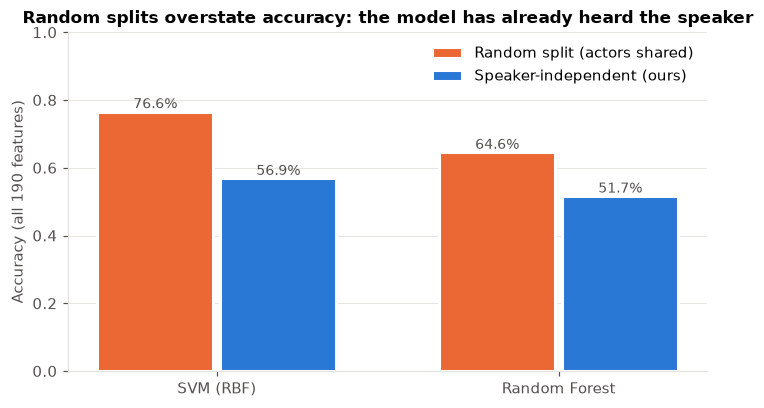

Protocol,Random split (actors shared),Speaker-independent (ours)
Model,,
Random Forest,0.646,0.517
SVM (RBF),0.766,0.569


In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from ser.evaluation import actor_folds
from ser.models import make_rf, make_svm

data = pd.read_csv(FEATURES_CSV)
X, y, actors = data[ALL].to_numpy(), data["emotion"].to_numpy(), data["actor"].to_numpy()
actor_cv = [(np.where(~np.isin(actors, t))[0], np.where(np.isin(actors, t))[0]) for t in actor_folds()]
random_cv = list(StratifiedKFold(6, shuffle=True, random_state=RANDOM_STATE).split(X, y))

leak = []
for label, model in [("SVM (RBF)", make_pipeline(StandardScaler(), make_svm(k=X.shape[1], C=10))),
                     ("Random Forest", make_pipeline(StandardScaler(), make_rf(k=X.shape[1])))]:
    for split_name, cv in [("Random split (actors shared)", random_cv), ("Speaker-independent (ours)", actor_cv)]:
        pred = cross_val_predict(model, X, y, cv=cv, n_jobs=4)
        leak.append({"Model": label, "Protocol": split_name, "Accuracy": (pred == y).mean()})
leak = pd.DataFrame(leak)
leak.to_csv(RESULTS_DIR / "leakage_check.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
models_ = leak.Model.unique()
for j, (prot, color) in enumerate([("Random split (actors shared)", "#eb6834"), ("Speaker-independent (ours)", "#2a78d6")]):
    vals = leak[leak.Protocol == prot].set_index("Model").loc[models_, "Accuracy"]
    xs = np.arange(len(models_)) + (j - 0.5) * 0.36
    ax.bar(xs, vals, width=0.34, color=color, label=prot, edgecolor="white", linewidth=2)
    for x, v in zip(xs, vals):
        ax.text(x, v + 0.01, f"{v:.1%}", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(range(len(models_)), models_)
ax.set_ylabel("Accuracy (all 190 features)")
ax.set_ylim(0, 1)
ax.set_title("Random splits overstate accuracy: the model has already heard the speaker")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
save(fig, "17_leakage_random_vs_speaker_split")
plt.show()
leak.pivot(index="Model", columns="Protocol", values="Accuracy").round(3)

## 8. Accuracy vs cost
Higher and further left is better. Feature selection reduces the size of the final model. The selection step itself costs time *once*, during training.

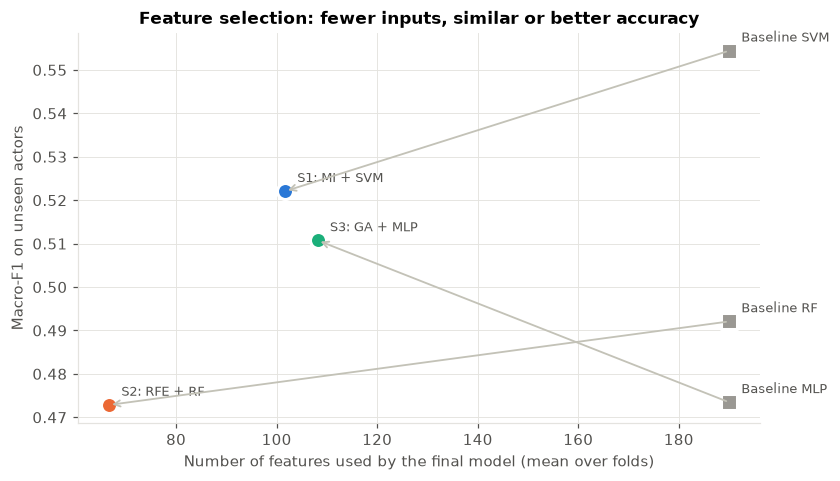

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.6))
for n, f in folds.items():
    sol = RUNS[n][2]
    color = SOLUTION_COLORS[n] if sol else GREY
    ax.scatter(f.n_features.mean(), f.macro_f1.mean(), s=110, color=color,
               marker="o" if sol else "s", edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(n.replace(" (all features)", ""), (f.n_features.mean(), f.macro_f1.mean()),
                textcoords="offset points", xytext=(8, 6), fontsize=8.5, color=INK_2)
for clf, b, s in pairs:
    ax.annotate("", xy=(folds[s].n_features.mean(), folds[s].macro_f1.mean()),
                xytext=(folds[b].n_features.mean(), folds[b].macro_f1.mean()),
                arrowprops=dict(arrowstyle="->", color="#c3c2b7", lw=1.2))
ax.set_xlabel("Number of features used by the final model (mean over folds)")
ax.set_ylabel("Macro-F1 on unseen actors")
ax.set_title("Feature selection: fewer inputs, similar or better accuracy")
save(fig, "16_accuracy_vs_features")
plt.show()

## 9. Accuracy per held-out actor
Each dot is one of the 24 actors, scored by the model that never heard them. The spread shows how much recognition depends on the individual speaker.

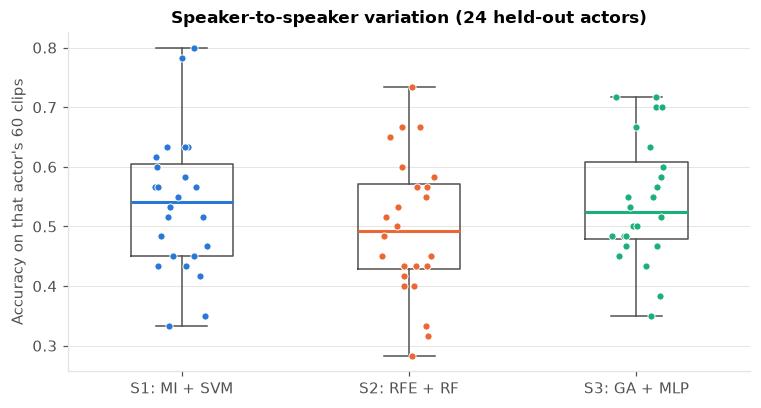

,S1: MI + SVM,S2: RFE + RF,S3: GA + MLP
count,24.000,24.000,24.000
mean,0.538,0.499,0.543
std,0.116,0.117,0.104
min,0.333,0.283,0.350
25%,0.450,0.429,0.479
50%,0.542,0.492,0.525
75%,0.604,0.571,0.608
max,0.800,0.733,0.717


In [13]:
per_actor = pd.DataFrame({n: o.assign(ok=o.y_true == o.y_pred).groupby("actor").ok.mean()
                          for n, o in oof.items() if RUNS[n][2]})
fig, ax = plt.subplots(figsize=(8, 4))
for i, n in enumerate(sol_names):
    vals = per_actor[n]
    ax.boxplot(vals, positions=[i], widths=0.45, showfliers=False,
               medianprops=dict(color=SOLUTION_COLORS[n], lw=2), boxprops=dict(color=INK_2),
               whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2))
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(vals)), vals, s=22, color=SOLUTION_COLORS[n], zorder=3,
               edgecolor="white", linewidth=0.6)
ax.set_xticks(range(3), sol_names)
ax.set_ylabel("Accuracy on that actor's 60 clips")
ax.set_title("Speaker-to-speaker variation (24 held-out actors)")
ax.grid(axis="x", visible=False)
save(fig, "18_per_actor_accuracy")
plt.show()
per_actor.describe().round(3)

## 10. Key findings
Printed from the numbers above, so this text always matches the results.

In [14]:
best = max(sol_names, key=lambda n: folds[n].macro_f1.mean())
for _, b, s in pairs:
    d = folds[s].macro_f1.mean() - folds[b].macro_f1.mean()
    print(f"{s}: macro-F1 {folds[s].macro_f1.mean():.3f} vs {folds[b].macro_f1.mean():.3f} baseline "
          f"({d:+.3f}) using {folds[s].n_features.mean():.0f} instead of 190 features")
print(f"\nBest solution: {best}")
easiest, hardest = per_class.loc[sol_names].mean().idxmax(), per_class.loc[sol_names].mean().idxmin()
print(f"Easiest emotion: {easiest}; hardest: {hardest}")
gap = leak.pivot(index="Model", columns="Protocol", values="Accuracy")
print("Random-split inflation:", (gap.iloc[:, 0] - gap.iloc[:, 1]).round(3).to_dict())

S1: MI + SVM: macro-F1 0.522 vs 0.554 baseline (-0.032) using 102 instead of 190 features
S2: RFE + RF: macro-F1 0.473 vs 0.492 baseline (-0.019) using 67 instead of 190 features
S3: GA + MLP: macro-F1 0.511 vs 0.473 baseline (+0.037) using 108 instead of 190 features

Best solution: S1: MI + SVM
Easiest emotion: Calm; hardest: Sad
Random-split inflation: {'Random Forest': 0.129, 'SVM (RBF)': 0.197}
